In [4]:
import pandas as pd
import tifffile
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/raw/"

In [3]:
df = pd.read_csv(filepath_or_buffer=f"{file_path}wells.csv")
df

,well_id,x,y,z
0,Well_0067,-999.00,388.56,-113.37
1,Well_0435,-999.00,1132.00,-68.02
2,Well_0199,-999.00,1277.21,-43.81
3,Well_0213,1286.20,836.52,-26.54
4,Well_0794,3918.96,1410.94,-115.29
...,...,...,...,...
850,Well_0072,1461.41,1502.93,-81.34
851,Well_0107,1565.86,767.86,-116.05
852,Well_0271,1432.38,1212.33,-43.33
853,Well_0436,1022.23,849.38,69.58


x, y, z — координаты определенной точки, x пр. [0; 5000], y пр. [0; 5000] z пр. [-150; -5]. Well_id — индекс определенной строки данных.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 855 entries, 0 to 854
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   well_id  855 non-null    str    
 1   x        855 non-null    float64
 2   y        843 non-null    float64
 3   z        847 non-null    float64
dtypes: float64(3), str(1)
memory usage: 34.4 KB


In [5]:
df.describe()

,x,y,z
count,855.000000,843.000000,847.000000
mean,1897.352117,1825.879739,-66.504179
std,1515.235728,1234.071787,51.473919
min,-999.000000,16.090000,-139.980000
25%,857.970000,893.380000,-103.880000
50%,1186.850000,1204.570000,-72.380000
75%,3603.795000,3172.195000,-36.705000
max,4975.900000,4991.740000,139.980000


count — количество элементов, mean — среднее значение (сумма всех элементов разделить на кол-во), std — среднее отклонение (сумма всех разностей значений и среднего значения, возведенных в квадрат, разделить на количество -1 и извдечь корень). Формула: $$s = \sqrt{\frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}}.$$ min и max — максимальное и минимальное значения, 50% — значения, меньше которых 50% других значений (аналогично больше). 25% — 25 процентов всех значений меньше этого числа ( аналогично и для 75%).

Очистка данных: 1 - постараться восстановить ошибочные значения, 2 - удалить nan, 3 - удалить дубликаты

In [29]:
display(df[(df["x"] < 0) | (df["x"] > 5000)])

display(df[(df["x"] < 0) | (df["x"] > 5000)].count())

,well_id,x,y,z
0,Well_0067,-999.0,388.56,-113.37
1,Well_0435,-999.0,1132.00,-68.02
2,Well_0199,-999.0,1277.21,-43.81
66,Well_0097,-999.0,919.04,119.47
111,Well_0543,-999.0,3267.33,-87.08
193,Well_0080,-999.0,1343.13,-75.28
216,Well_0333,-999.0,698.76,-124.27
247,Well_0809,-999.0,1252.22,-123.77
320,Well_0528,-999.0,3441.20,-138.14
381,Well_0023,-999.0,801.21,-106.65


well_id    26
x          26
y          26
z          26
dtype: int64

По x нет значений выше нормы. Восстановить значения невозможно. Значит необходимо удалить значения, с внешними ссылками, т.к. такие данные не представляют никакой ценности.

In [25]:
df[df["x"].isna()]

,well_id,x,y,z


Значений Nan по x нет. Удалять нечего.

In [26]:
df[(df["y"] < 0) | (df["y"] > 5000)]

,well_id,x,y,z


Невалидных значений для y не нашлось.

In [30]:
df[df["y"].isna()]

,well_id,x,y,z
26,Well_0771,2951.74,NaN,-134.29
56,Well_0024,572.58,NaN,-54.96
90,Well_0050,471.09,NaN,-53.03
177,Well_0003,1194.31,NaN,-131.50
183,Well_0486,573.32,NaN,-113.58
322,Well_0580,4340.09,NaN,-58.78
512,Well_0713,3123.32,NaN,-29.88
521,Well_0323,754.53,NaN,-57.27
567,Well_0739,4715.38,NaN,-59.09
593,Well_0695,3362.80,NaN,-72.23


In [32]:
df[(df["z"] > -5) | (df["z"] < -150)]

,well_id,x,y,z
9,Well_0810,4637.81,2953.27,40.22
11,Well_0637,4475.79,3254.64,38.36
14,Well_0312,1329.63,868.08,88.71
21,Well_0560,3851.75,3477.69,101.61
31,Well_0469,840.85,987.95,70.66
39,Well_0769,3664.01,1493.63,68.94
46,Well_0140,630.74,611.48,33.19
66,Well_0097,-999.00,919.04,119.47
93,Well_0300,1188.89,1008.93,88.39
115,Well_0683,4367.33,4362.92,75.93


Предположим, что ошибка по оси z заключается в отсутствии -, если координаты лежат на положительном промежутке от 5 до 150.

In [34]:
df[((df["z"] > -5) | (df["z"] < -150)) & ((df["z"] < 5) | (df["z"] > 150)) ]

,well_id,x,y,z


In [35]:
df[df["z"].isna()]

,well_id,x,y,z
86,Well_0630,4131.50,3739.97,NaN
141,Well_0356,699.24,828.78,NaN
169,Well_0282,1198.64,599.40,NaN
222,Well_0583,3871.35,3783.24,NaN
257,Well_0668,4225.56,3126.69,NaN
702,Well_0831,3542.83,3694.58,NaN
807,Well_0505,4279.29,3519.54,NaN
812,Well_0190,545.55,1133.28,NaN


Такие значения нельзя исправить и пользы они не несут, так что удаляем.

In [37]:
df["round_x"] = df["x"].round(0)
df["round_y"] = df["y"].round(0)

df[df.duplicated(subset=["round_x", "round_y", "z"], keep=False)]

,well_id,x,y,z,round_x,round_y
5,Well_0544,3984.60,3094.10,-131.42,3985.0,3094.0
19,Well_0817,790.08,1058.93,-78.18,790.0,1059.0
22,Well_0276,1138.63,528.93,-92.96,1139.0,529.0
23,Well_0621,4442.21,3522.66,-128.39,4442.0,3523.0
43,Well_0031,819.49,1191.58,-125.17,819.0,1192.0
...,...,...,...,...,...,...
786,Well_0776,4366.61,4013.22,-30.33,4367.0,4013.0
803,Well_0465,966.30,973.08,-110.39,966.0,973.0
806,Well_0838,4686.94,2938.86,-15.47,4687.0,2939.0
830,Well_0806,362.85,853.20,-48.27,363.0,853.0


По итогу нужно: по x удалить все значение где -999.0, по y удалить все значения где nan, удалить все значения по z где nan, восстановаить значения по z, где координата положительна и в промежутке от 5 до 150 путем добавления -, удалить все дубликаты у которых совпадают все 3 координаты для которых округления до целых по осям x и y. Удалять нужно со всех связанных таблиц.

In [3]:
df = pd.read_csv(f"{file_path}cores.csv")
df

,well_id,z_top,z_bottom,lithology
0,Well_0248,-72.0,-111.0,Sand
1,Well_0290,-143.0,-183.0,Loam
2,Well_0183,-29.0,-43.0,Sand
3,Well_0260,-50.0,-84.0,Gravel
4,Well_0612,-45.0,-76.0,Sand
...,...,...,...,...
3833,Well_0252,0.0,-17.0,Sand
3834,Well_0287,-24.0,-53.0,Loam
3835,Well_0194,-102.0,-128.0,Clay
3836,Well_0775,-39.0,-75.0,Clay


Для очистки датасета: 1) убрать ошибочные значения, 2) убрать none, 3) убрать дубликаты.

In [7]:
df[df["z_top"] > 0]

,well_id,z_top,z_bottom,lithology
31,Well_0004,28.0,-96.0,Gravel
212,Well_0706,11.0,-111.0,Clay
262,Well_0282,37.0,-122.0,Loam
570,Well_0571,12.0,-100.0,Loam
739,Well_0039,12.0,-97.0,Sand
749,Well_0093,10.0,-154.0,Sand
1262,Well_0469,13.0,-75.0,Sand
1421,Well_0564,27.0,-40.0,Clay
1522,Well_0775,25.0,-39.0,Loam
1596,Well_0392,17.0,-28.0,Clay


In [9]:
df[df["z_top"] < df["z_bottom"]]

,well_id,z_top,z_bottom,lithology


In [11]:
df[df["z_bottom"] > 0]

,well_id,z_top,z_bottom,lithology


In [15]:
df[df["z_bottom"] < -200]

,well_id,z_top,z_bottom,lithology
690,Well_0112,-169.0,-208.0,Sand
1052,Well_0272,-174.0,-208.0,Sand
3051,Well_0184,-166.0,-204.0,Sand
3792,Well_0606,-177.0,-214.0,Clay


In [16]:
df.describe()

,z_top,z_bottom
count,3838.000000,3817.000000
mean,-47.990620,-74.204611
std,40.063436,40.660278
min,-177.000000,-214.000000
25%,-76.000000,-103.000000
50%,-42.000000,-70.000000
75%,-14.000000,-39.000000
max,37.000000,-11.000000


В итоге для очистки датасета необходимо:

- изменить знак для всех положительных значений из z_top (в z_bottom таких чисел не найдено),
- попробовать восстановить nan значения из z_bottom при помощи поиска верхней, нижней границы из соседнего слоя.
- попробовать восстановить nan значения из lithology, при помощи поиска дубликата по well_id, z_bottom, z_top.
- попробовать восстановать значения из lithology, которые не входят в список ["Sand", "Loam", "Gravel", "Clay"] путем устранения опечаток и приведения к нижнему регистру.
- если 2 слоя пересекаются и образуют внешний и внутренний слои удалить внутренний.
- загрузить таблицу wells, найти координаты всех вышек с идентичными координатами, из таблицы cores выбрать самую глубокую, запомнить ее айди, назвать доварительной, и удалить по id все записи с идентичными координатами из таблицы cores, кроме приоритетной.
- при пересечении двух слоев не образующих внешний и внутренние слои изменить границы одного из слоев во избежание конфликта.
- если координаты z_top, z_bottom перепутаны — поменять местами
- очистить все дубликаты по всем строкам.
- удалить все безнадежные nan, из z_top, z_bottom, lithology которые не были удалены предыдущими действиями.

In [35]:
df[df["well_id"].isna()]

,well_id,z_top,z_bottom,lithology


In [3]:
df_head = pd.read_csv(f"{file_path}head.csv")

In [6]:
df_head.describe()

,head
count,1610.000000
mean,29.108186
std,12.005200
min,-95.800000
25%,18.472500
50%,34.920000
75%,36.400000
max,40.530000


Для очистки данного датафрейма необходимо заменить знак во всех отрицательных значениях в head, удалить nan из head и t, восстановить эти значения невозможно, удалить дубликаты, дубликатами будут считаться данные в которых совпдают well_id и t, проверить данные и даты на корректность.

In [7]:
df_head

,well_id,t,head
0,Well_0498,14.01.2024,37.40
1,Well_0688,21.09.2022,15.22
2,Well_0446,15.11.2024,35.76
3,Well_0574,09.08.2021,NaN
4,Well_0818,17.03.2025,40.53
...,...,...,...
1620,Well_0799,14.01.2021,25.73
1621,Well_0432,12.11.2021,37.28
1622,Well_0146,02.02.2022,35.14
1623,Well_0329,28.01.2023,36.54


In [3]:
df_pumping = pd.read_csv(f"{file_path}pumping.csv")

In [4]:
df_pumping

,well_id,t,pumping_rate,units
0,Well_0003,01.03.2022,359.79,m3/day
1,Well_0518,01.07.2024,1162.81,m3/day
2,Well_0005,01.12.2025,327.50,m3/day
3,Well_0505,01.10.2022,930.95,m3/day
4,Well_0010,01.10.2022,356.73,m3/day
...,...,...,...,...
3235,Well_0516,01.04.2021,1368.65,m3/day
3236,Well_0516,01.03.2024,1434.06,m3/day
3237,Well_0518,01.11.2025,1139.50,m3/day
3238,Well_0512,01.09.2025,908.72,m3/day


In [24]:
df_pumping[(df_pumping["units"] == "l/s")]

,well_id,t,pumping_rate,units,t_datetime
28,Well_0507,01.12.2023,14.082,l/s,2023-12-01
37,Well_0528,01.05.2021,15.286,l/s,2021-05-01
38,Well_0502,01.08.2025,12.119,l/s,2025-08-01
48,Well_0012,01.12.2022,3.345,l/s,2022-12-01
54,Well_0504,01.03.2023,16.340,l/s,2023-03-01
...,...,...,...,...,...
3052,Well_0529,01.11.2021,12.669,l/s,2021-11-01
3162,Well_0521,01.01.2025,16.058,l/s,2025-01-01
3190,Well_0011,01.09.2020,2.557,l/s,2020-09-01
3212,Well_0501,01.10.2021,12.212,l/s,2021-10-01


Необходимо будет умножить на 1000 l/s и разделить на 24 * 60 * 60 чтобы получить нужные единицы измерения.

In [6]:
df_pumping[df_pumping["pumping_rate"] < 0]

,well_id,t,pumping_rate,units
52,Well_0503,01.04.2023,-1405.94,m3/day
182,Well_0007,01.11.2020,-406.21,m3/day
245,Well_0529,01.06.2022,-1198.35,m3/day
272,Well_0011,01.11.2025,-323.85,m3/day
504,Well_0511,01.04.2023,-1410.26,m3/day
561,Well_0510,01.11.2025,-1069.95,m3/day
705,Well_0522,01.11.2025,-1089.40,m3/day
851,Well_0517,01.02.2025,-1472.84,m3/day
1101,Well_0010,01.09.2025,-288.62,m3/day
1140,Well_0522,01.10.2022,-917.69,m3/day


У всех отриыательных нужно будет изменить знак

In [11]:
df_pumping[df_pumping["pumping_rate"].isna()]

,well_id,t,pumping_rate,units
64,Well_0517,01.01.2023,NaN,m3/day
145,Well_0514,01.10.2020,NaN,m3/day
212,Well_0001,01.08.2023,NaN,m3/day
552,Well_0001,01.10.2025,NaN,m3/day
557,Well_0008,01.06.2020,NaN,m3/day
577,Well_0001,01.08.2024,NaN,m3/day
588,Well_0509,01.10.2023,NaN,m3/day
733,Well_0005,01.08.2024,NaN,m3/day
848,Well_0527,01.08.2021,NaN,m3/day
936,Well_0501,01.12.2024,NaN,l/s


Все NaN значения из pumping_rate необходимо будет удалить.

In [21]:
df_pumping["t_datetime"] = pd.to_datetime(df_pumping["t"], format="%d.%m.%Y", errors="coerce")

bad_values = (
    (df_pumping["t_datetime"].isna()) |
    (df_pumping["t_datetime"] < "2020-01-01") |
    (df_pumping["t_datetime"] > "2025-12-31")
)

df_pumping[bad_values]

,well_id,t,pumping_rate,units,t_datetime


Итого для полной очистки датасета с данными об откачках необходимо:
- В столбце units найти все значения l/s и заменить их на m3/day, а результат из pumping_rate / 1000 * (24 * 60 * 60)
- Удалить NaN значепния из pumping_rate
- Проверить корректнеость дат, а также их вхождение в временной интревал с 01.01.2020 до 10.31.2025
- Отрицательные значения из pumping_rate зхаменить на полоительные
- Удалить дубликаты, строка считается дубликатом другой, в том случае, если совпадают строки целеком.

In [3]:
df_concentration = pd.read_csv(f"{file_path}concentration.csv")
df_concentration

,well_id,t,concentration
0,Well_0416,13.01.2022,0.21
1,Well_0781,01.05.2023,NaN
2,Well_0110,02.02.2025,0.31
3,Well_0750,06.08.2020,-42.24
4,Well_0150,27.07.2024,1.74
...,...,...,...
2840,Well_0637,09.01.2020,0.03
2841,Well_0765,2023-08-08,ND
2842,Well_0118,02.05.2023,25.48
2843,Well_0681,23.06.2025,0.5


In [5]:
df_concentration[df_concentration["concentration"].isna()]

,well_id,t,concentration
1,Well_0781,01.05.2023,NaN
172,Well_0632,28.04.2023,NaN
239,Well_0486,24.04.2024,NaN
332,Well_0174,26.09.2022,NaN
345,Well_0464,14.02.2020,NaN
399,Well_0109,23.10.2023,NaN
622,Well_0665,01.09.2022,NaN
635,Well_0663,03.04.2024,NaN
682,Well_0622,21.12.2021,NaN
901,Well_0165,07.07.2020,NaN


In [6]:
df_concentration[df_concentration["concentration"] == "ND"]

,well_id,t,concentration
52,Well_0698,01.03.2023,ND
136,Well_0149,07.08.2025,ND
196,Well_0565,20.11.2021,ND
319,Well_0677,18.03.2024,ND
567,Well_0529,14.06.2022,ND
1038,Well_0573,24.03.2022,ND
1114,Well_0686,26.04.2023,ND
1120,Well_0577,19.10.2025,ND
1179,Well_0591,29.11.2023,ND
1252,Well_0572,13.05.2022,ND


In [8]:
df_concentration[df_concentration["t"].isna()]

,well_id,t,concentration
70,Well_0471,NaN,0.35
780,Well_0599,NaN,0.13
874,Well_0014,NaN,90.86
895,Well_0193,NaN,139.43
977,Well_0121,NaN,417.77
979,Well_0112,NaN,348.2
1082,Well_0695,NaN,0.05
1088,Well_0060,NaN,872.24
1208,Well_0219,NaN,0.45
1237,Well_0338,NaN,21.29


In [17]:
df_concentration[(df_concentration["concentration"] != "ND") & (df_concentration["concentration"] != "Error") & (~(df_concentration["concentration"].isna())) & (df_concentration["concentration"] != "<0.05")].head(30)

,well_id,t,concentration
0,Well_0416,13.01.2022,0.21
2,Well_0110,02.02.2025,0.31
3,Well_0750,06.08.2020,-42.24
4,Well_0150,27.07.2024,1.74
5,Well_0355,27.12.2023,0.27
6,Well_0570,18.10.2025,21.42
7,Well_0149,26.06.2021,1.8
8,Well_0528,24.06.2021,0.11
9,Well_0327,27.11.2021,434.55
10,Well_0010,09.01.2024,20.45


Восстановить значения из 2 и 3 строки невозможно, так что для очистки датасета необходимо:
- Удалить NaN значения из столбца t
- Удалить NaN значения из столбца concentration.
- Удалить невалидные значения ND, Error, <0.05
- Попробовать убрать невалидные, отрицательные значения

In [6]:
df_abstraction = pd.read_csv(f"{file_path}abstraction.csv")

In [7]:
df_abstraction

,intake_name,x_center,y_center,t,total_abstraction_m3_day
0,Заречный водозабор,4000.0,3500.0,01.01.2020,26714.6
1,Заречный водозабор,4000.0,3500.0,01.02.2020,31722.3
2,Заречный водозабор,4000.0,3500.0,01.03.2020,38836.4
3,Заречный водозабор,4000.0,3500.0,01.04.2020,41624.0
4,Заречный водозабор,4000.0,3500.0,01.05.2020,42837.7
...,...,...,...,...,...
67,Заречный водозабор,4000.0,3500.0,01.08.2025,40293.2
68,Заречный водозабор,4000.0,3500.0,01.09.2025,35794.1
69,Заречный водозабор,4000.0,3500.0,01.10.2025,29547.1
70,Заречный водозабор,4000.0,3500.0,01.11.2025,28858.6


In [12]:
df_abstraction[df_abstraction["total_abstraction_m3_day"].isna()]

,intake_name,x_center,y_center,t,total_abstraction_m3_day
5,Заречный водозабор,4000.0,3500.0,01.06.2020,NaN
45,Заречный водозабор,4000.0,3500.0,01.10.2023,NaN
51,Заречный водозабор,4000.0,3500.0,01.04.2024,NaN


Для очистки этого датасета необходимо:
- Удалить NaN значения из total_abstraction_m3_day
- Проверить корректность дат.

In [43]:
df_abstraction[df_abstraction["t"].isna()]

,intake_name,x_center,y_center,t,total_abstraction_m3_day,t_datetime


In [44]:
df_test = pd.read_csv(f"{file_path}queries_test.csv")

In [45]:
df_test

,query_id,x,y,z,t
0,Q_0001,1444.29,924.32,-86.98,28.06.2024
1,Q_0002,3013.90,2212.32,-38.01,30.07.2022
2,Q_0003,3180.09,3104.40,-52.31,27.07.2025
3,Q_0004,3371.66,2417.84,-87.11,20.02.2026
4,Q_0005,1646.35,1536.63,-83.42,06.08.2024
...,...,...,...,...,...
595,Q_0596,3816.33,3491.77,-32.24,24.05.2024
596,Q_0597,2169.66,1421.34,-54.87,11.06.2022
597,Q_0598,1711.11,2293.67,-116.73,15.02.2024
598,Q_0599,2510.13,2214.94,-29.55,06.10.2025


In [54]:
df_test[df_test["z"] > 0]

,query_id,x,y,z,t


In [56]:
df_recharge = pd.read_csv(f"{file_path}recharge.csv")

In [57]:
display(df_recharge)
display(df_recharge.info())
display(df_recharge.describe())

,zone,t,recharge_mm
0,Industrial_Zone,01.01.2020,0.65
1,Water_Intake_Zone,01.01.2020,0.00
2,Forest_Zone,01.01.2020,1.89
3,Industrial_Zone,01.02.2020,4.65
4,Water_Intake_Zone,01.02.2020,1.81
...,...,...,...
211,Water_Intake_Zone,01.11.2025,NaN
212,Forest_Zone,01.11.2025,13.44
213,Industrial_Zone,01.12.2025,6.88
214,Water_Intake_Zone,01.12.2025,5.57


<class 'pandas.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   zone         216 non-null    str    
 1   t            216 non-null    str    
 2   recharge_mm  210 non-null    float64
dtypes: float64(1), str(2)
memory usage: 10.3 KB


None

,recharge_mm
count,210.000000
mean,-19.092429
std,196.150262
min,-999.000000
25%,5.900000
50%,16.020000
75%,25.405000
max,75.510000


In [61]:
df_recharge[df_recharge["recharge_mm"].isna()]

,zone,t,recharge_mm
44,Forest_Zone,01.03.2021,NaN
117,Industrial_Zone,01.04.2023,NaN
136,Water_Intake_Zone,01.10.2023,NaN
147,Industrial_Zone,01.02.2024,NaN
169,Water_Intake_Zone,01.09.2024,NaN
211,Water_Intake_Zone,01.11.2025,NaN


In [62]:
df_recharge[df_recharge["recharge_mm"] < 0]

,zone,t,recharge_mm
7,Water_Intake_Zone,01.03.2020,-999.0
16,Water_Intake_Zone,01.06.2020,-999.0
45,Industrial_Zone,01.04.2021,-999.0
50,Forest_Zone,01.05.2021,-999.0
79,Water_Intake_Zone,01.03.2022,-999.0
107,Forest_Zone,01.12.2022,-999.0
146,Forest_Zone,01.01.2024,-999.0
159,Industrial_Zone,01.06.2024,-999.0


In [63]:
df_recharge["t_datetime"] = pd.to_datetime(df_recharge["t"], format="%d.%m.%Y", errors="coerce")

In [64]:
display(df_recharge.describe())

,recharge_mm,t_datetime
count,210.000000,216
mean,-19.092429,2022-12-16 06:40:00
min,-999.000000,2020-01-01 00:00:00
25%,5.900000,2021-06-23 12:00:00
50%,16.020000,2022-12-16 12:00:00
75%,25.405000,2024-06-08 12:00:00
max,75.510000,2025-12-01 00:00:00
std,196.150262,NaN


Для очистки данного датафрейма необходимо:
- Удалить значения -999.0 из recharge_mm
- Удалить NaN значения из recharge_mm

In [69]:
df_sources = pd.read_csv(f"{file_path}sources.csv")

In [70]:
df_sources

,source_id,name,x,y,z_top,z_bottom,start_date,end_date,estimated_release_rate_g_day
0,SRC_01,Цех обезжиривания №1,950.0,1020.0,-15.0,-45.0,01.01.2020,NaN,450.0
1,SRC_02,Старый шламонакопитель,1120.5,940.0,-5.0,-30.0,15.03.2020,31.12.2023,320.0
2,SRC_03,Склад растворителей,1030.0,1100.0,-10.0,-25.0,10.06.2020,NaN,180.0
3,SRC_04,Дренажный коллектор Юг,890.0,850.0,-20.0,-55.0,2020-02-01,NaN,-999.0
4,SRC_05,Аварийный сброс 2021,1450.0,1300.0,-8.0,-20.0,12.08.2021,15.09.2022,850.0


In [6]:
permeability = tifffile.imread(f"{file_path}permeability.tif")
permeability

array([[-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
         4.6035032e+00,  4.6035433e+00,  4.6035409e+00],
       [-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
         4.6033096e+00,  4.6033502e+00,  4.6033483e+00],
       [-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
         4.6029463e+00,  4.6029873e+00,  4.6029859e+00],
       ...,
       [ 4.6081295e+00,  4.6082115e+00,  4.6083941e+00, ...,
         6.0647917e+00,  6.1446438e+00,  6.2280817e+00],
       [ 4.6099052e+00,  4.6099811e+00,  4.6101508e+00, ...,
         5.9714828e+00,  6.0475936e+00,  6.1272230e+00],
       [ 4.6108108e+00,  4.6108832e+00,  4.6110468e+00, ...,
         5.8829031e+00,  5.9553618e+00,  6.0312672e+00]],
      shape=(500, 500), dtype=float32)

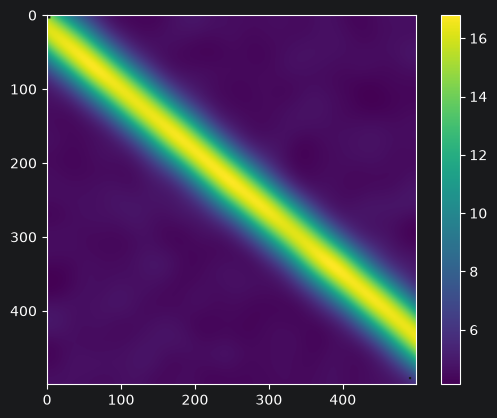

In [7]:
permeability[permeability == -9999.0] = np.nan
plt.imshow(permeability, cmap="viridis")
plt.colorbar()

In [8]:
permeability.shape

(500, 500)